<a href="https://colab.research.google.com/github/DibikshyaShrestha20/Machine-learning-with-Python/blob/main/Air_Quality_code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
D!pip install pandas numpy xgboost scikit-learn matplotlib seaborn

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split, GridSearchCV, learning_curve
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/xgboost_code/data/XGBoost_data.csv')
df.head()

,aod,lst,NDVI,soil_moisture,pm10,pm25,O3,elevation,surface_pressure
0,1.033,25.53,0.2967,0.321072,112.0,182.0,0.131271,1353,83796.535156
1,0.173,24.39,0.3706,0.333978,50.0,98.0,0.114578,1353,84271.480469
2,0.158,24.39,0.3706,0.333978,50.0,98.0,0.114578,1353,84271.480469
3,0.181,25.27,0.3706,0.331775,36.0,89.0,0.110911,1353,84351.183594
4,0.284,25.27,0.3706,0.331775,36.0,89.0,0.110911,1353,84351.183594


In [ ]:
for col in df.columns:
    Q1, Q3 = df[col].quantile([0.25, 0.75])
    IQR = Q3 - Q1
    df[col] = np.clip(df[col], Q1 - 1.5 * IQR, Q3 + 1.5 * IQR)

In [ ]:
X = df.drop(['pm10', 'pm25'], axis=1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled

array([[ 2.18778742,  0.2581244 , -0.11414797, ...,  1.54773308,
         1.75441472, -1.01551913],
       [-1.08614761,  0.0566922 ,  0.59587436, ..., -1.15373105,
         1.75441472,  0.50334769],
       [-1.16080975,  0.0566922 ,  0.59587436, ..., -1.15373105,
         1.75441472,  0.50334769],
       ...,
       [-1.01646294, -1.13776535, -0.85203316, ..., -0.26022862,
         0.97062214,  0.04292565],
       [ 0.11840165, -1.13776535, -0.85203316, ..., -0.26022862,
         0.97062214,  0.04292565],
       [-1.40968357, -0.8550535 , -0.83666055, ...,  2.39812091,
         0.97062214, -0.6617548 ]])

In [ ]:
param_grid = {
    'n_estimators': [600, 800, 1000],
    'max_depth': [6],
    'learning_rate': [0.1, 0.15],
    'subsample': [0.6, 0.7]
}

In [ ]:
y = df['pm10']
label = 'PM10'
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

grid_search = GridSearchCV(
    estimator=XGBRegressor(random_state=42, n_jobs=-1),
    param_grid=param_grid,
    scoring='neg_mean_squared_error',
    cv=5,
    verbose=1
)
grid_search.fit(X_train, y_train)
pm10_model = grid_search.best_estimator_
print("Best Hyperparameters:", grid_search.best_params_)

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best Hyperparameters: {'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 1000, 'subsample': 0.7}


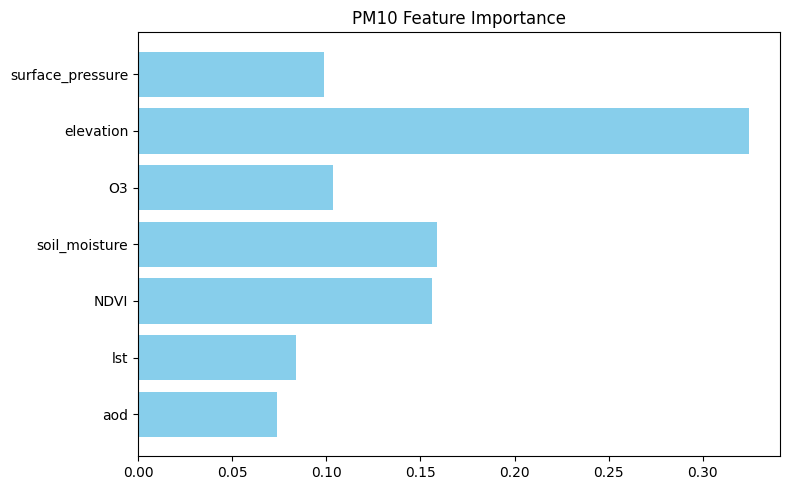

In [ ]:
# Feature Importance Plot
plt.figure(figsize=(8, 5))
plt.barh(X.columns, pm10_model.feature_importances_, color='skyblue')
plt.title(f"{label} Feature Importance")
plt.tight_layout()
import os
save_path = "/content/C:\\Model"
os.makedirs(save_path, exist_ok=True)
plt.savefig(os.path.join(save_path, "feature_importance_PM10.png"))  # Save the plot
plt.show()

MAE: 5.8826
RMSE: 9.8626
R2 Score: 0.9101


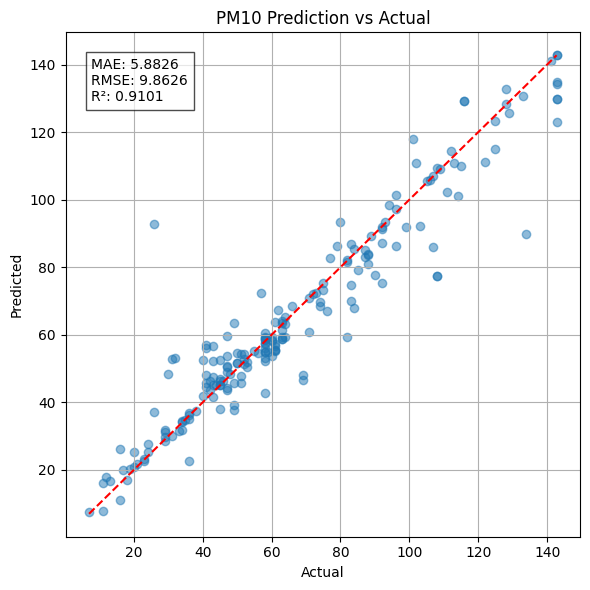

In [ ]:
import os
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import matplotlib.pyplot as plt

# Create the directory if it doesn't exist
save_path = r"C:\Model"
os.makedirs(save_path, exist_ok=True)

# Predicted values from the model
preds = pm10_model.predict(X_test)

# Evaluation metrics
mae = mean_absolute_error(y_test, preds)
mse = mean_squared_error(y_test, preds)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, preds)

# Adjusted R2
n = X_test.shape[0]
p = X_test.shape[1]
adj_r2 = 1 - ((1 - r2) * (n - 1) / (n - p - 1))

# Print metrics
print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R2 Score: {r2:.4f}")

# Prediction vs Actual Plot
plt.figure(figsize=(6, 6))
plt.scatter(y_test, preds, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title(f"{label} Prediction vs Actual")

# Add metrics to the plot
metrics_text = (f"MAE: {mae:.4f}\n"
                f"RMSE: {rmse:.4f}\n"
                f"R²: {r2:.4f}")
plt.text(0.05, 0.95, metrics_text, transform=plt.gca().transAxes, fontsize=10, verticalalignment='top', bbox=dict(facecolor='white', alpha=0.7))

plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(save_path, "prediction_vs_actual_PM25.png"))  # Save the plot
plt.show()

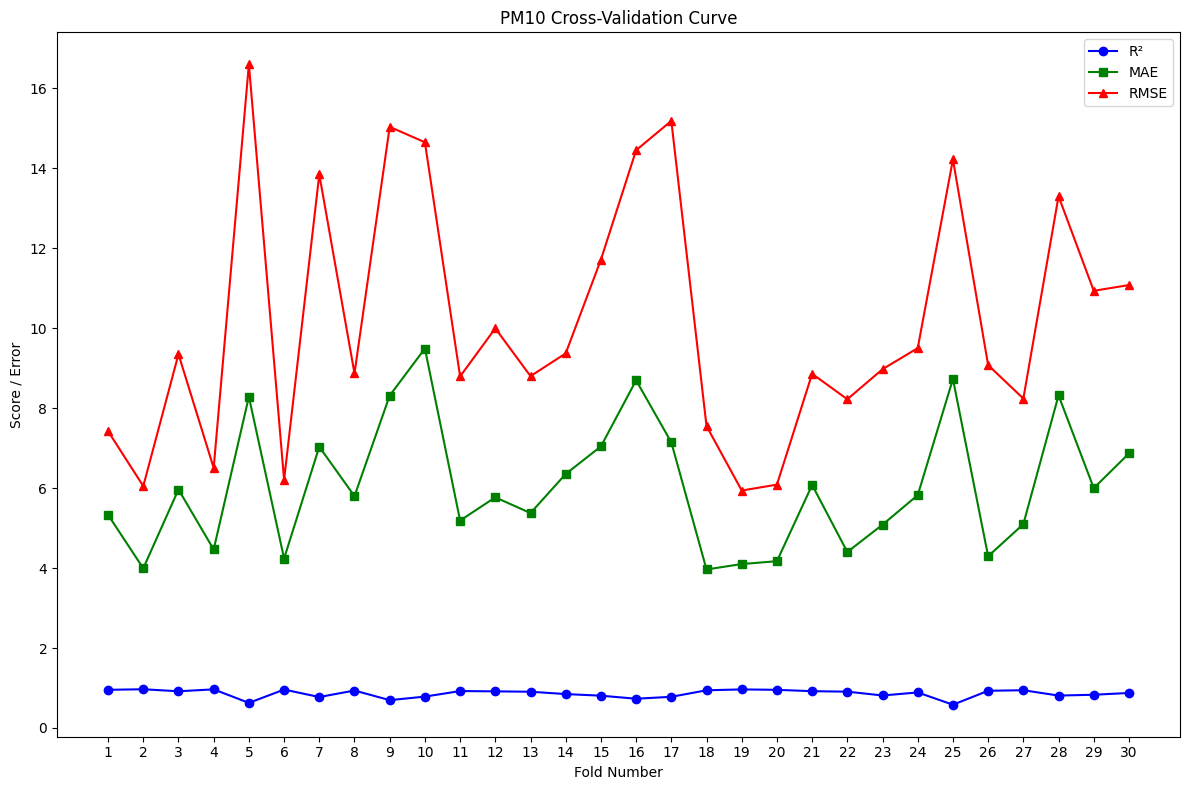

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import KFold
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt
import os

# Load Data (Assuming df and X_scaled are already defined)
# If not, add your data loading and preprocessing code here

# Target variable
y_pm10 = df['pm10']

# Define KFold
kf = KFold(n_splits=30, shuffle=True, random_state=42)

r2_scores = []
mae_scores = []
rmse_scores = []

# Cross-validation loop
for train_index, val_index in kf.split(X_scaled, y_pm10):
    X_train, X_val = X_scaled[train_index], X_scaled[val_index]
    y_train_pm10, y_val_pm10 = y_pm10.iloc[train_index], y_pm10.iloc[val_index]

    model = XGBRegressor()
    model.fit(X_train, y_train_pm10)
    y_pred = model.predict(X_val)

    r2 = r2_score(y_val_pm10, y_pred)
    mae = mean_absolute_error(y_val_pm10, y_pred)
    rmse = np.sqrt(mean_squared_error(y_val_pm10, y_pred))  # Calculate RMSE

    r2_scores.append(r2)
    mae_scores.append(mae)
    rmse_scores.append(rmse)

# Plotting the Cross-Validation Curve
plt.figure(figsize=(12, 8))  # Adjust figure size

plt.plot(range(1, 31), r2_scores, marker='o', linestyle='-', color='blue', label='R²')
plt.plot(range(1, 31), mae_scores, marker='s', linestyle='-', color='green', label='MAE')
plt.plot(range(1, 31), rmse_scores, marker='^', linestyle='-', color='red', label='RMSE')

plt.title('PM10 Cross-Validation Curve')
plt.xlabel('Fold Number')
plt.ylabel('Score / Error')
#plt.grid(True) # Remove this line to remove the grid
plt.xticks(range(1, 31))
plt.legend()  # Add legend to distinguish the metrics
plt.tight_layout()

# Save the plot to the specified output file
output_path = "/content/C:\\Model"
os.makedirs(output_path, exist_ok=True)
plt.savefig(os.path.join(output_path, "pm10_cross_validation_curve.png"))
plt.show()

In [ ]:
y = df['pm25']
label = 'PM25'
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

grid_search = GridSearchCV(
    estimator=XGBRegressor(random_state=42, n_jobs=-1),
    param_grid=param_grid,
    scoring='neg_mean_squared_error',
    cv=5,
    verbose=1
)
grid_search.fit(X_train, y_train)
pm25_model = grid_search.best_estimator_
print("Best Hyperparameters:", grid_search.best_params_)

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best Hyperparameters: {'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 800, 'subsample': 0.6}


MAE: 7.0602
MSE: 141.0218
RMSE: 11.8753
R2 Score: 0.8866
Adjusted R2 Score: 0.8823


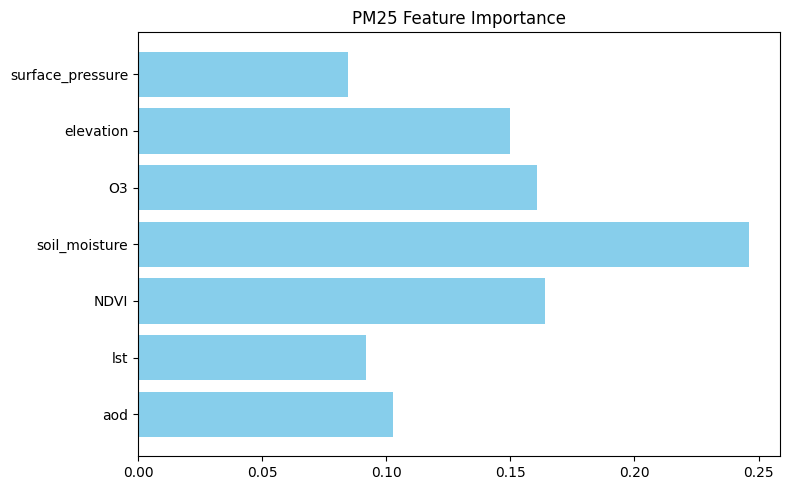

In [ ]:
import os
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import matplotlib.pyplot as plt

# Create the directory if it doesn't exist
save_path = r"C:\Model"
os.makedirs(save_path, exist_ok=True)

# Predicted values from the model
preds = pm25_model.predict(X_test)

# Evaluation metrics
mae = mean_absolute_error(y_test, preds)
mse = mean_squared_error(y_test, preds)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, preds)

# Adjusted R2
n = X_test.shape[0]
p = X_test.shape[1]
adj_r2 = 1 - ((1 - r2) * (n - 1) / (n - p - 1))

# Print metrics
print(f"MAE: {mae:.4f}")
print(f"MSE: {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R2 Score: {r2:.4f}")
print(f"Adjusted R2 Score: {adj_r2:.4f}")

# Feature Importance Plot
plt.figure(figsize=(8, 5))
plt.barh(X.columns, pm25_model.feature_importances_, color='skyblue')
plt.title(f"{label} Feature Importance")
plt.tight_layout()
plt.savefig(os.path.join(save_path, "feature_importance.png"))  # Save the plot
plt.show()



In [ ]:
y = df['pm25']
label = 'PM2.5'
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

grid_search = GridSearchCV(
    estimator=XGBRegressor(random_state=42, n_jobs=-1),
    param_grid=param_grid,
    scoring='neg_mean_squared_error',
    cv=5,
    verbose=1
)
grid_search.fit(X_train, y_train)
pm25_model = grid_search.best_estimator_
print("Best Hyperparameters:", grid_search.best_params_)

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best Hyperparameters: {'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 800, 'subsample': 0.6}


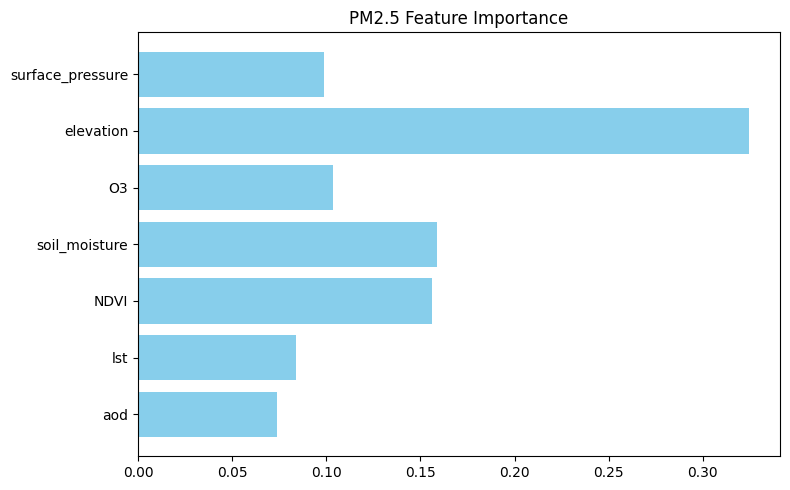

In [ ]:
# Feature Importance Plot
plt.figure(figsize=(8, 5))
plt.barh(X.columns, pm10_model.feature_importances_, color='skyblue')
plt.title(f"{label} Feature Importance")
plt.tight_layout()
import os
save_path = "/content/C:\\Model"
os.makedirs(save_path, exist_ok=True)
plt.savefig(os.path.join(save_path, "feature_importance_PM25.png"))  # Save the plot
plt.show()


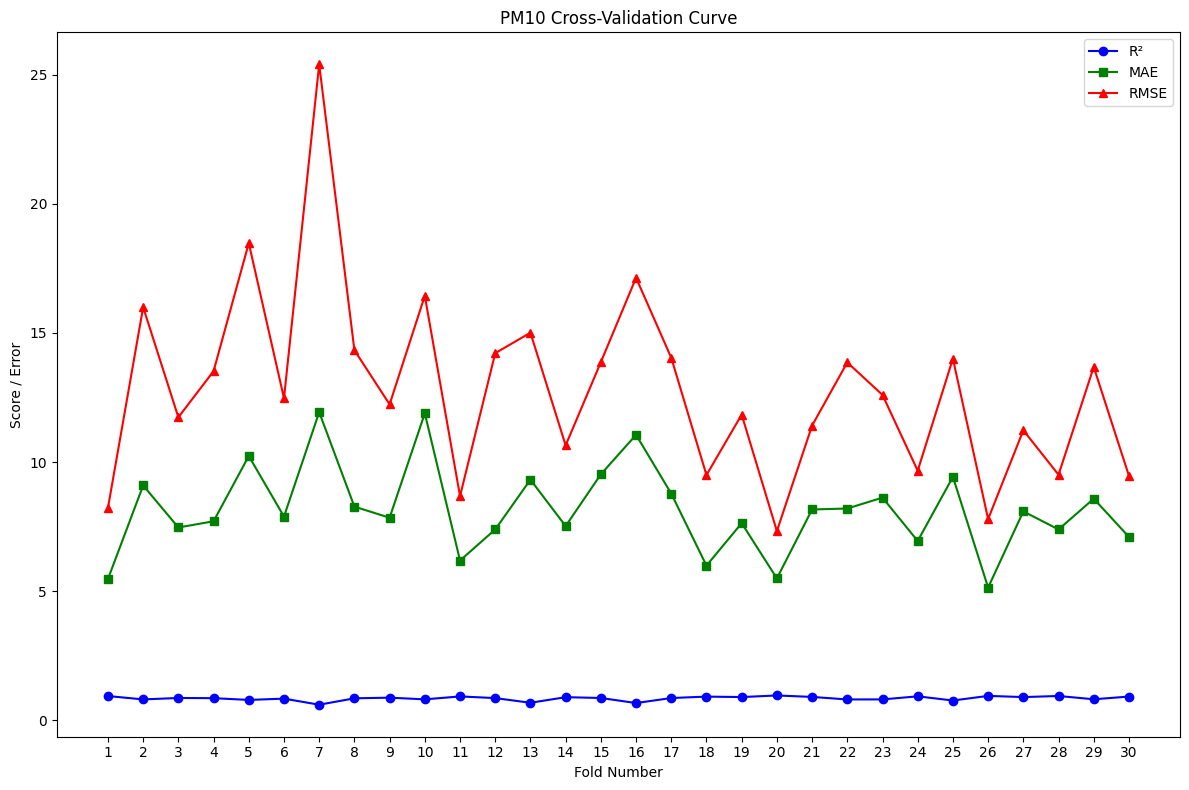

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import KFold
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt
import os

# Load Data (Assuming df and X_scaled are already defined)
# If not, add your data loading and preprocessing code here

# Target variable
y_pm25 = df['pm25']

# Define KFold
kf = KFold(n_splits=30, shuffle=True, random_state=42)

r2_scores = []
mae_scores = []
rmse_scores = []

# Cross-validation loop
for train_index, val_index in kf.split(X_scaled, y_pm25):
    X_train, X_val = X_scaled[train_index], X_scaled[val_index]
    y_train_pm25, y_val_pm25 = y_pm25.iloc[train_index], y_pm25.iloc[val_index]

    model = XGBRegressor()
    model.fit(X_train, y_train_pm25)
    y_pred = model.predict(X_val)

    r2 = r2_score(y_val_pm25, y_pred)
    mae = mean_absolute_error(y_val_pm25, y_pred)
    rmse = np.sqrt(mean_squared_error(y_val_pm25, y_pred))  # Calculate RMSE

    r2_scores.append(r2)
    mae_scores.append(mae)
    rmse_scores.append(rmse)

# Plotting the Cross-Validation Curve
plt.figure(figsize=(12, 8))  # Adjust figure size

plt.plot(range(1, 31), r2_scores, marker='o', linestyle='-', color='blue', label='R²')
plt.plot(range(1, 31), mae_scores, marker='s', linestyle='-', color='green', label='MAE')
plt.plot(range(1, 31), rmse_scores, marker='^', linestyle='-', color='red', label='RMSE')

plt.title('PM10 Cross-Validation Curve')
plt.xlabel('Fold Number')
plt.ylabel('Score / Error')
#plt.grid(True) # Remove this line to remove the grid
plt.xticks(range(1, 31))
plt.legend()  # Add legend to distinguish the metrics
plt.tight_layout()

# Save the plot to the specified output file
output_path = "/content/C:\\Model"
os.makedirs(output_path, exist_ok=True)
plt.savefig(os.path.join(output_path, "pm25_cross_validation_curve.png"))
plt.show()

R² scores for each fold: [0.9546924208561766, 0.96852047245368, 0.9181471479002954, 0.9657164420670448, 0.6273326625061759, 0.9605973727388711, 0.7741295250564674, 0.9368858748131907, 0.6958787958301238, 0.7845435207602571, 0.9235743303373259, 0.9157135197169209, 0.9066391177947024, 0.8480159929244535, 0.8076547933641661, 0.731505379348686, 0.7797957487878878, 0.9427765073343722, 0.9643534354435657, 0.9544182049351467, 0.9200659570401067, 0.9082506238746938, 0.8126146485987483, 0.8887868433816887, 0.5819521516793973, 0.9303872731466887, 0.9441224014273566, 0.8103833748163948, 0.8310639674569178, 0.875402526342337]
Average R² score for PM10: 0.862130701091128
MAE scores for each fold: [5.330975070144191, 3.993900183475379, 5.965507391727332, 4.464729410229308, 8.28620806607333, 4.239274400653261, 7.0349712082833955, 5.799456596374512, 8.315829992294312, 9.491836547851562, 5.188721626996994, 5.769785657525063, 5.37576550245285, 6.353687644004822, 7.043549060821533, 8.696387469768524, 7.1

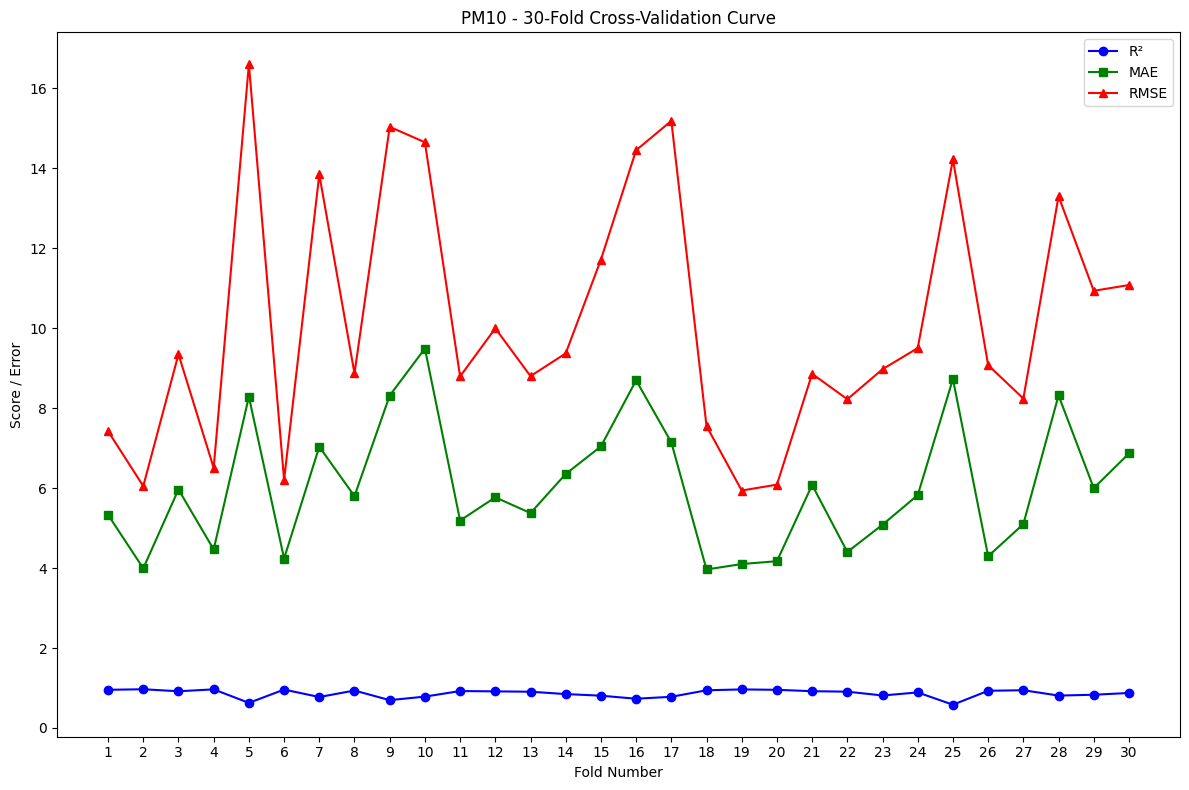

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import KFold
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt

# Load Data (Assuming df and X_scaled are already defined)
# If not, add your data loading and preprocessing code here

# Target variable
y_pm10 = df['pm10']

# Define KFold
kf = KFold(n_splits=30, shuffle=True, random_state=42)

r2_scores = []
mae_scores = []
rmse_scores = []

# Cross-validation loop
for train_index, val_index in kf.split(X_scaled, y_pm10):
    X_train, X_val = X_scaled[train_index], X_scaled[val_index]
    y_train_pm10, y_val_pm10 = y_pm10.iloc[train_index], y_pm10.iloc[val_index]

    model = XGBRegressor()
    model.fit(X_train, y_train_pm10)
    y_pred = model.predict(X_val)

    r2 = r2_score(y_val_pm10, y_pred)
    mae = mean_absolute_error(y_val_pm10, y_pred)
    rmse = np.sqrt(mean_squared_error(y_val_pm10, y_pred))  # Calculate RMSE

    r2_scores.append(r2)
    mae_scores.append(mae)
    rmse_scores.append(rmse)

print("R² scores for each fold:", r2_scores)
print("Average R² score for PM10:", np.mean(r2_scores))
print("MAE scores for each fold:", mae_scores)
print("Average MAE score for PM10:", np.mean(mae_scores))
print("RMSE scores for each fold:", rmse_scores)
print("Average RMSE score for PM10:", np.mean(rmse_scores))

# Plotting the Cross-Validation Curve
plt.figure(figsize=(12, 8))  # Adjust figure size

plt.plot(range(1, 31), r2_scores, marker='o', linestyle='-', color='blue', label='R²')
plt.plot(range(1, 31), mae_scores, marker='s', linestyle='-', color='green', label='MAE')
plt.plot(range(1, 31), rmse_scores, marker='^', linestyle='-', color='red', label='RMSE')

plt.title('PM10 - 30-Fold Cross-Validation Curve')
plt.xlabel('Fold Number')
plt.ylabel('Score / Error')
#plt.grid(True) # Remove this line to remove the grid
plt.xticks(range(1, 31))
plt.legend()  # Add legend to distinguish the metrics
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Predictions
preds = pm25_model.predict(X_test)

# Standard metrics
mae = mean_absolute_error(y_test, preds)
rmse = np.sqrt(mean_squared_error(y_test, preds))
r2 = r2_score(y_test, preds)

# Modified R² (Adjusted R²)
n = X_test.shape[0]  # number of samples
p = X_test.shape[1]  # number of predictors/features
adjusted_r2 = 1 - (1 - r2) * ((n - 1) / (n - p - 1))

print(f"{label} XGBoost Evaluation:")
print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²: {r2:.2f}")
print(f"Adjusted R²: {adjusted_r2:.2f}")

PM2.5 XGBoost Evaluation:
MAE: 7.06
RMSE: 11.88
R²: 0.89
Adjusted R²: 0.88


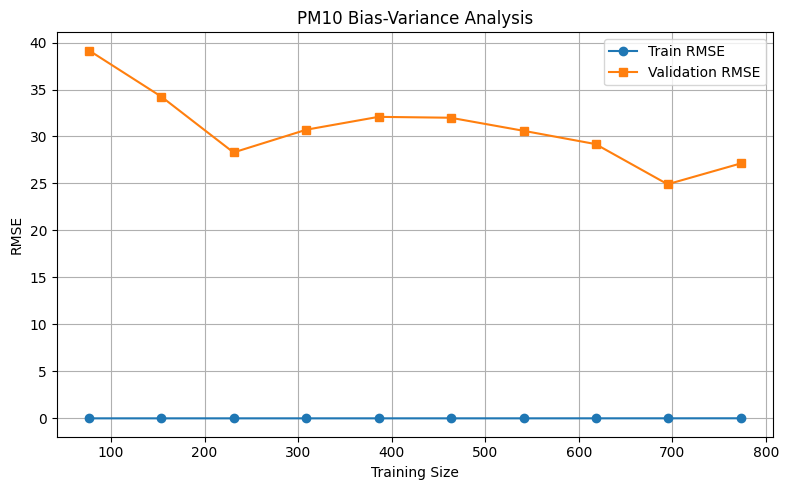

In [ ]:
train_sizes, train_scores, val_scores = learning_curve(
    pm10_model, X_scaled, y,
    train_sizes=np.linspace(0.1, 1.0, 10),
    cv=5,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)

train_rmse = np.sqrt(-train_scores.mean(axis=1))
val_rmse = np.sqrt(-val_scores.mean(axis=1))

plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_rmse, marker='o', label='Train RMSE')
plt.plot(train_sizes, val_rmse, marker='s', label='Validation RMSE')
plt.xlabel("Training Size")
plt.ylabel("RMSE")
plt.title(f"{label} Bias-Variance Analysis")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

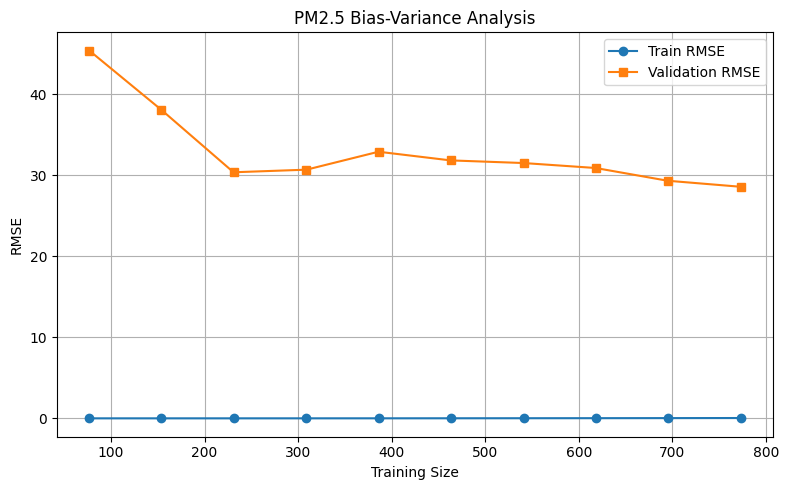

In [ ]:
train_sizes, train_scores, val_scores = learning_curve(
    pm25_model, X_scaled, y,
    train_sizes=np.linspace(0.1, 1.0, 10),
    cv=5,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)

train_rmse = np.sqrt(-train_scores.mean(axis=1))
val_rmse = np.sqrt(-val_scores.mean(axis=1))

plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_rmse, marker='o', label='Train RMSE')
plt.plot(train_sizes, val_rmse, marker='s', label='Validation RMSE')
plt.xlabel("Training Size")
plt.ylabel("RMSE")
plt.title(f"{label} Bias-Variance Analysis")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
import joblib

# Export scaler
joblib.dump(scaler, '/content/drive/MyDrive/xgboost_code/scaler.pkl')

# Export PM10 model
joblib.dump(pm10_model, '/content/drive/MyDrive/xgboost_code/pm10_model.pkl')

# Export PM2.5 model
joblib.dump(pm25_model, '/content/drive/MyDrive/xgboost_code/pm25_model.pkl')

['/content/drive/MyDrive/xgboost_code/pm25_model.pkl']

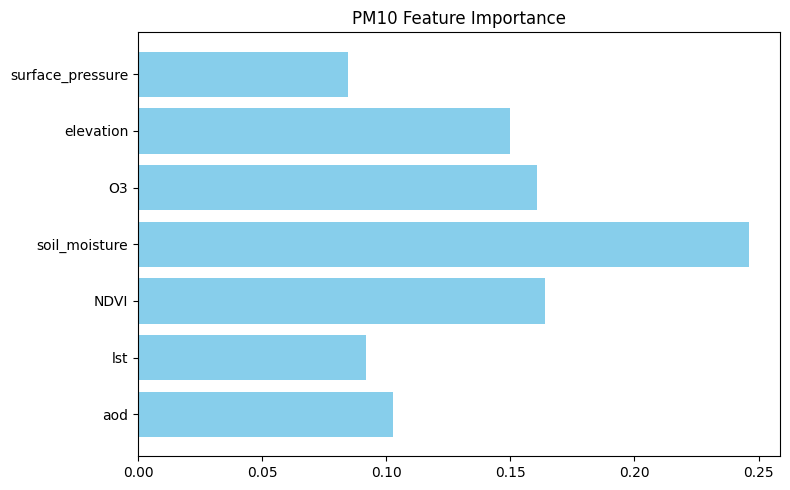

In [ ]:
# Feature Importance Plot
plt.figure(figsize=(8, 5))
plt.barh(X.columns, pm25_model.feature_importances_, color='skyblue')
plt.title(f"{label} Feature Importance")
plt.tight_layout()
import os
save_path = "/content/C:\\Model"
os.makedirs(save_path, exist_ok=True)
plt.savefig(os.path.join(save_path, "feature_importance_PM25.png"))  # Save the plot
plt.show()



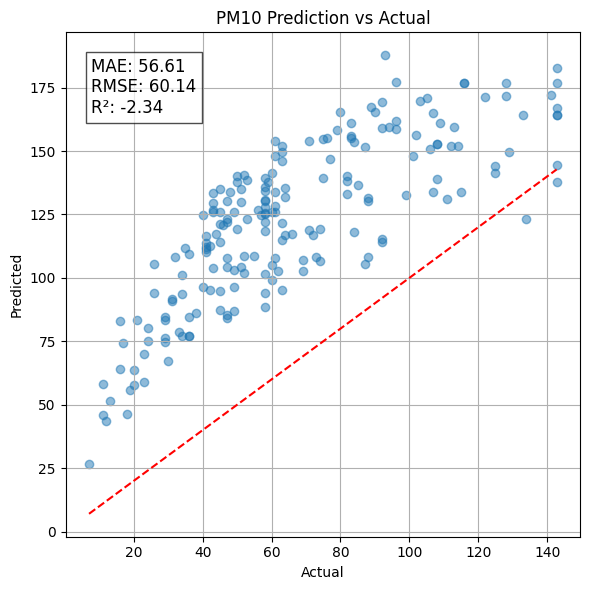

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import matplotlib.pyplot as plt
import os

# Predictions
preds = pm25_model.predict(X_test)

# Calculate the metrics
mae = mean_absolute_error(y_test, preds)
mse = mean_squared_error(y_test, preds)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, preds)

# Modified R² (Adjusted R²)
n = X_test.shape[0]  # number of samples
p = X_test.shape[1]  # number of predictors/features
adjusted_r2 = 1 - (1 - r2) * ((n - 1) / (n - p - 1))

# Plot the actual vs predicted values
plt.figure(figsize=(6, 6))
plt.scatter(y_test, preds, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title(f"{label} Prediction vs Actual")

# Display the metrics on the plot
metrics_text = (f"MAE: {mae:.2f}\n"
                f"RMSE: {rmse:.2f}\n"
                f"R²: {r2:.2f}")
plt.text(0.05, 0.95, metrics_text, transform=plt.gca().transAxes, fontsize=12, verticalalignment='top', bbox=dict(facecolor='white', alpha=0.7))

plt.grid(True)
plt.tight_layout()

# Save the plot to the specified output file
output_dir = "/content/C:\\Model"
os.makedirs(output_dir, exist_ok=True)
plt.savefig(os.path.join(output_dir, f"{label}_prediction_vs_actual.png"))
plt.show()

R² scores for each fold: [0.9399507306898559, 0.80894354613404, 0.8647423090001909, 0.8574656089897869, 0.7894463139528846, 0.8391879331025878, 0.6043151145000656, 0.8514536615174153, 0.876990552632691, 0.8115319526914194, 0.9244979019064528, 0.8607165102820783, 0.6790660446587706, 0.8954186529886278, 0.8647286774901808, 0.668328399094126, 0.8628000790244645, 0.9177230816732099, 0.9004678411637268, 0.9623172521106123, 0.9058007142738598, 0.8076090298531104, 0.8095406634751015, 0.9283671421014424, 0.7666882004023363, 0.9460886589685434, 0.8996014721854038, 0.9420006085897185, 0.8145174081147855, 0.9195680559835712]
Average R² score for PM10: 0.8506624705850353
MAE scores for each fold: [5.471410462350557, 9.095744277491715, 7.466913974646366, 7.70823386221221, 10.236019828102805, 7.890085740522905, 11.933552135120738, 8.274906277656555, 7.84490168094635, 11.889590501785278, 6.187199592590332, 7.391515731811523, 9.319301843643188, 7.521026134490967, 9.52678632736206, 11.05575680732727, 8

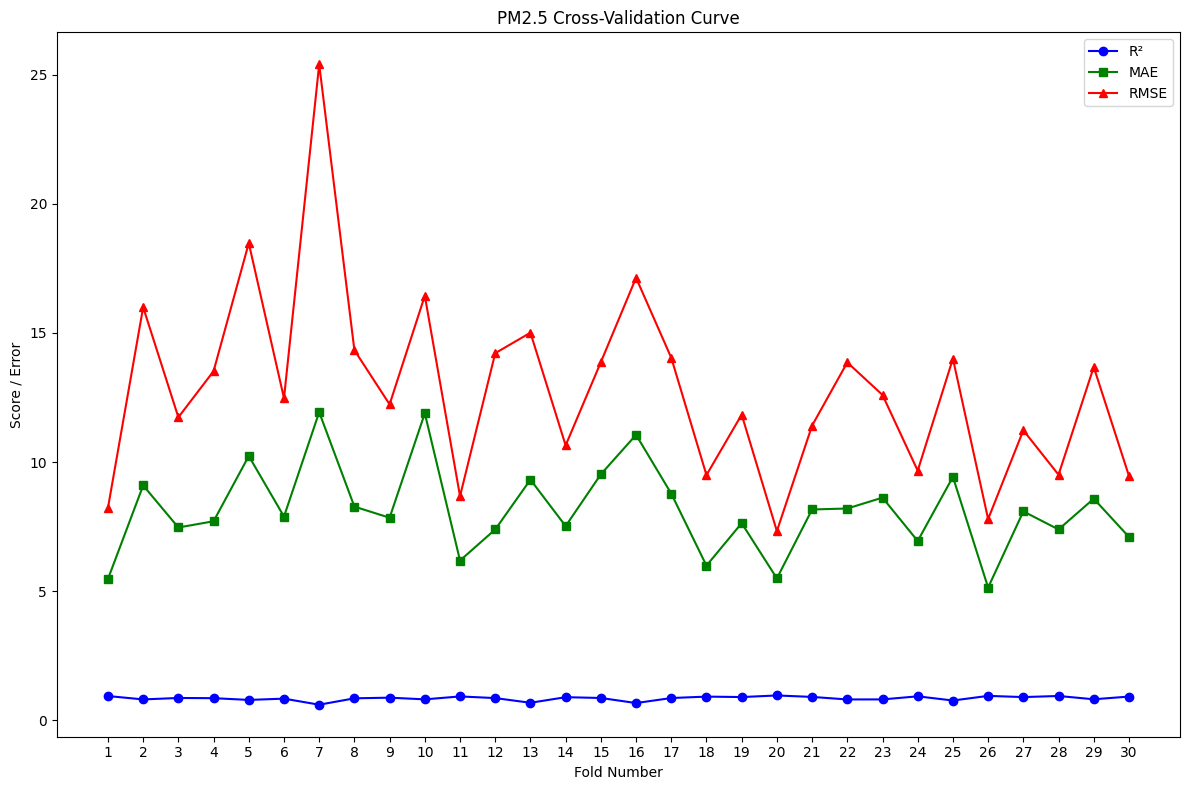

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import KFold
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt

# Load Data (Assuming df and X_scaled are already defined)
# If not, add your data loading and preprocessing code here

# Target variable
y_pm25 = df['pm25']

# Define KFold
kf = KFold(n_splits=30, shuffle=True, random_state=42)

r2_scores = []
mae_scores = []
rmse_scores = []

# Cross-validation loop
for train_index, val_index in kf.split(X_scaled, y_pm25):
    X_train, X_val = X_scaled[train_index], X_scaled[val_index]
    y_train_pm25, y_val_pm25 = y_pm25.iloc[train_index], y_pm25.iloc[val_index]

    model = XGBRegressor()
    model.fit(X_train, y_train_pm25)
    y_pred = model.predict(X_val)

    r2 = r2_score(y_val_pm25, y_pred)
    mae = mean_absolute_error(y_val_pm25, y_pred)
    rmse = np.sqrt(mean_squared_error(y_val_pm25, y_pred))  # Calculate RMSE

    r2_scores.append(r2)
    mae_scores.append(mae)
    rmse_scores.append(rmse)

print("R² scores for each fold:", r2_scores)
print("Average R² score for PM10:", np.mean(r2_scores))
print("MAE scores for each fold:", mae_scores)
print("Average MAE score for PM10:", np.mean(mae_scores))
print("RMSE scores for each fold:", rmse_scores)
print("Average RMSE score for PM10:", np.mean(rmse_scores))

# Plotting the Cross-Validation Curve
plt.figure(figsize=(12, 8))  # Adjust figure size

plt.plot(range(1, 31), r2_scores, marker='o', linestyle='-', color='blue', label='R²')
plt.plot(range(1, 31), mae_scores, marker='s', linestyle='-', color='green', label='MAE')
plt.plot(range(1, 31), rmse_scores, marker='^', linestyle='-', color='red', label='RMSE')

plt.title('PM2.5 Cross-Validation Curve')
plt.xlabel('Fold Number')
plt.ylabel('Score / Error')
#plt.grid(True) # Remove this line to remove the grid
plt.xticks(range(1, 31))
plt.legend()  # Add legend to distinguish the metrics
plt.tight_layout()

# Save the plot to the specified output file
output_path = r"C:\Model"
plt.savefig(f"{output_path}/pm25_cross_validation_curve.png")
plt.show()